<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/quantum_field_theory/qft_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Quantum Field Theory* — `qft_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# QFT Ch 3 Figures — Colab Notebook
**Quantum Field Theory · Chapter 3: Interacting Fields**

PSE Lab · SeoulTech · Tong (Cambridge)

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | $\phi^4$ potential, perturbation series, running coupling | §3.1 |
| fig02 | Wick's theorem, 1-loop self-energy, 4-point vertex | §3.2–3.3 |
| fig03 | S-matrix, differential & total cross section | §3.4 |
| fig04 | UV divergence, mass renormalization, RG beta-function | §3.5 |

---
## fig01 · Interaction Potential & Perturbation Theory (§3.1)

**Left**: $\phi^4$ potential for various $\lambda$. **Centre**: Perturbation series for ground state energy — higher orders diverge at large $\lambda$. **Right**: Running coupling constant — $\phi^4$ Landau pole, QED $\alpha$ increasing.

  saved -> figures/ch03/fig01_interaction.png


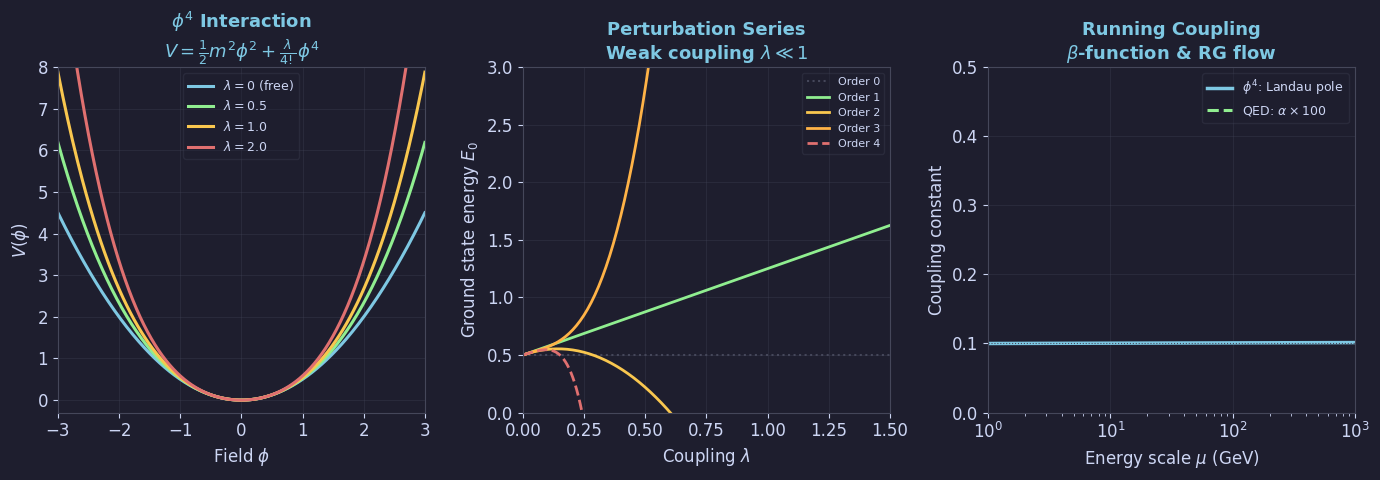

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch03'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig01: phi^4 potential + perturbation series ──────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: phi^4 potential for various lambda
ax = axes[0]
phi = np.linspace(-3, 3, 300)
for lam, col, lab in [(0, BLUE, r'$\lambda=0$ (free)'),
                       (0.5, GREEN, r'$\lambda=0.5$'),
                       (1.0, YELLOW, r'$\lambda=1.0$'),
                       (2.0, RED, r'$\lambda=2.0$')]:
    V = 0.5*phi**2 + (lam/24)*phi**4
    ax.plot(phi, V, color=col, lw=2.2, label=lab)
ax.set_xlabel(r'Field $\phi$'); ax.set_ylabel(r'$V(\phi)$')
ax.set_title(r'$\phi^4$ Interaction' + '\n'
             + r'$V=\frac{1}{2}m^2\phi^2+\frac{\lambda}{4!}\phi^4$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(-3, 3); ax.set_ylim(-0.3, 8)

# Centre: perturbation series — E(lambda) at various orders
ax2 = axes[1]
lam_arr = np.linspace(0, 1.5, 200)
# Ground state energy of anharmonic oscillator (1D analogy)
# E ~ 1/2 + (3/4)*lambda - (21/8)*lambda^2 + ... (weak coupling)
E0 = 0.5 * np.ones_like(lam_arr)
E1 = 0.5 + (3/4)*lam_arr
E2 = 0.5 + (3/4)*lam_arr - (21/8)*lam_arr**2
E3 = 0.5 + (3/4)*lam_arr - (21/8)*lam_arr**2 + (333/16)*lam_arr**3
# "exact" numerical
E_exact = 0.5 + (3/4)*lam_arr - (21/8)*lam_arr**2 + (333/16)*lam_arr**3 - (30885/128)*lam_arr**4
ax2.plot(lam_arr, E0,     color=EDGE,   lw=1.5, ls=':', label='Order 0')
ax2.plot(lam_arr, E1,     color=GREEN,  lw=2.0, label='Order 1')
ax2.plot(lam_arr, E2,     color=YELLOW, lw=2.0, label='Order 2')
ax2.plot(lam_arr, E3,     color=ORANGE, lw=2.0, label='Order 3')
ax2.plot(lam_arr, E_exact,color=RED,    lw=2.0, ls='--', label='Order 4')
ax2.set_xlabel(r'Coupling $\lambda$')
ax2.set_ylabel(r'Ground state energy $E_0$')
ax2.set_title('Perturbation Series\n' + r'Weak coupling $\lambda\ll 1$', color=BLUE)
ax2.legend(fontsize=8, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0, 1.5); ax2.set_ylim(0, 3)

# Right: coupling constant running (schematic)
ax3 = axes[2]
mu = np.linspace(1, 1000, 500)
# phi^4: lambda runs logarithmically
lam0 = 0.1
beta_coeff = 3/(16*np.pi**2)
lam_run = lam0 / (1 - lam0*beta_coeff*np.log(mu))
lam_run = np.where(lam_run > 5, np.nan, lam_run)
ax3.plot(mu, lam_run, color=BLUE, lw=2.5, label=r'$\phi^4$: Landau pole')
# QED: alpha runs up
alpha0 = 1/137
alpha_run = alpha0 / (1 - alpha0/(3*np.pi)*np.log(mu))
ax3.plot(mu, alpha_run*100, color=GREEN, lw=2.2, ls='--',
         label=r'QED: $\alpha\times100$')
ax3.axhline(lam0, color=EDGE, lw=0.8, ls=':')
ax3.set_xlabel(r'Energy scale $\mu$ (GeV)')
ax3.set_ylabel(r'Coupling constant')
ax3.set_xscale('log')
ax3.set_title('Running Coupling\n' + r'$\beta$-function & RG flow', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(1, 1000); ax3.set_ylim(0, 0.5)

plt.tight_layout(pad=1.2)
save('fig01_interaction.png', fig)


---
## fig02 · Wick's Theorem & Feynman Diagrams (§3.2–3.3)

**Left**: Wick's theorem — time-ordered product as sum over all contractions $\Delta_F$. **Centre**: 1-loop self-energy diagram in $\phi^4$ — tadpole bubble. **Right**: Tree-level 4-point vertex $-i\lambda$, amplitude $\mathcal{M}=-\lambda$.

  saved -> figures/ch03/fig02_wick_feynman.png


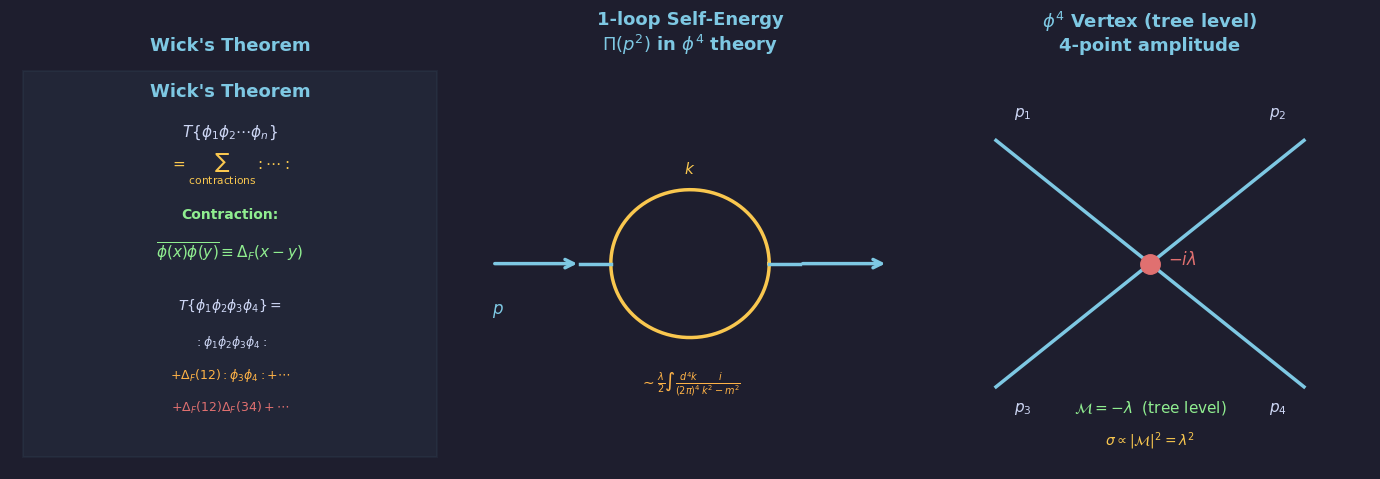

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch03'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig02: Wick's theorem + contraction diagrams ──────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Feynman propagator as Wick contraction
ax = axes[0]
ax.axis('off')
lines = [
    (0.50, 0.92, "Wick's Theorem", BLUE, 13, 'bold'),
    (0.50, 0.82, r'$T\{\phi_1\phi_2\cdots\phi_n\}$', FG, 11, 'normal'),
    (0.50, 0.73, r'$= \sum_{\rm contractions} :\cdots:$', YELLOW, 11, 'normal'),
    (0.50, 0.62, r'Contraction:', GREEN, 10, 'bold'),
    (0.50, 0.53, r'$\overline{\phi(x)\phi(y)} \equiv \Delta_F(x-y)$', GREEN, 11, 'normal'),
    (0.50, 0.40, r'$T\{\phi_1\phi_2\phi_3\phi_4\}=$', FG, 10, 'normal'),
    (0.50, 0.31, r'$:\phi_1\phi_2\phi_3\phi_4:$', FG, 9, 'normal'),
    (0.50, 0.23, r'$+\Delta_F(12):\phi_3\phi_4:+\cdots$', ORANGE, 9, 'normal'),
    (0.50, 0.15, r'$+\Delta_F(12)\Delta_F(34)+\cdots$', RED, 9, 'normal'),
]
for (xp, yp, txt, col, fs, fw) in lines:
    ax.text(xp, yp, txt, ha='center', va='center', color=col,
            fontsize=fs, fontweight=fw, transform=ax.transAxes)
rect = plt.Rectangle((0.03, 0.03), 0.94, 0.94, fill=True,
                      facecolor=BLUE, alpha=0.05,
                      edgecolor=BLUE, lw=1.5, transform=ax.transAxes)
ax.add_patch(rect)
ax.set_title("Wick's Theorem", color=BLUE)

# Centre: 2-point function at 1-loop (schematic diagram)
ax2 = axes[1]
ax2.axis('off')
# Draw propagator line with loop
# External lines
ax2.annotate('', xy=(0.25, 0.5), xytext=(0.05, 0.5),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5, mutation_scale=15),
             xycoords='axes fraction', textcoords='axes fraction')
ax2.annotate('', xy=(0.95, 0.5), xytext=(0.75, 0.5),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5, mutation_scale=15),
             xycoords='axes fraction', textcoords='axes fraction')
# Loop bubble
theta = np.linspace(0, 2*np.pi, 200)
cx, cy, r = 0.5, 0.5, 0.18
ax2.plot(cx + r*np.cos(theta), cy + r*np.sin(theta),
         color=YELLOW, lw=2.5, transform=ax2.transAxes)
# Connect lines to loop
ax2.plot([0.25, cx-r], [0.5, cy], color=BLUE, lw=2.5, transform=ax2.transAxes)
ax2.plot([cx+r, 0.75], [cy, 0.5], color=BLUE, lw=2.5, transform=ax2.transAxes)
# Labels
ax2.text(0.05, 0.38, '$p$', color=BLUE, fontsize=12, transform=ax2.transAxes)
ax2.text(0.50, 0.72, '$k$', color=YELLOW, fontsize=11, ha='center', transform=ax2.transAxes)
ax2.text(0.50, 0.20,
         r'$\sim \frac{\lambda}{2}\int\frac{d^4k}{(2\pi)^4}\frac{i}{k^2-m^2}$',
         color=ORANGE, fontsize=10, ha='center', transform=ax2.transAxes)
ax2.set_title('1-loop Self-Energy\n' + r'$\Pi(p^2)$ in $\phi^4$ theory', color=BLUE)

# Right: 4-point vertex diagram (tree level)
ax3 = axes[2]
ax3.axis('off')
cx, cy = 0.5, 0.5
legs = [(0.15,0.80),(0.85,0.80),(0.15,0.20),(0.85,0.20)]
labels = ['$p_1$','$p_2$','$p_3$','$p_4$']
for (lx, ly), lab in zip(legs, labels):
    ax3.plot([lx, cx], [ly, cy], color=BLUE, lw=2.5, transform=ax3.transAxes)
    dx = 0.06 * np.sign(lx - cx); dy = 0.06 * np.sign(ly - cy)
    ax3.text(lx - dx, ly + dy, lab, color=FG, fontsize=11,
             ha='center', transform=ax3.transAxes)
ax3.plot(cx, cy, 'o', color=RED, ms=14, transform=ax3.transAxes, zorder=5)
ax3.text(cx + 0.04, cy, r'$-i\lambda$', color=RED, fontsize=12,
         transform=ax3.transAxes)
ax3.text(0.50, 0.14,
         r'$\mathcal{M}=-\lambda$  (tree level)',
         color=GREEN, fontsize=11, ha='center', transform=ax3.transAxes)
ax3.text(0.50, 0.06,
         r'$\sigma\propto|\mathcal{M}|^2=\lambda^2$',
         color=YELLOW, fontsize=10, ha='center', transform=ax3.transAxes)
ax3.set_title(r'$\phi^4$ Vertex (tree level)' + '\n4-point amplitude',
              color=BLUE)

plt.tight_layout(pad=1.2)
save('fig02_wick_feynman.png', fig)


---
## fig03 · S-matrix & Cross Section (§3.4)

**Left**: S-matrix structure $S=1+iT$, unitarity, optical theorem. **Centre**: Differential cross section $d\sigma/d\Omega$ vs $\theta$ — tree vs 1-loop. **Right**: Total cross section $\sigma(E)$ — threshold behaviour at $E=2m$.

  saved -> figures/ch03/fig03_smatrix.png


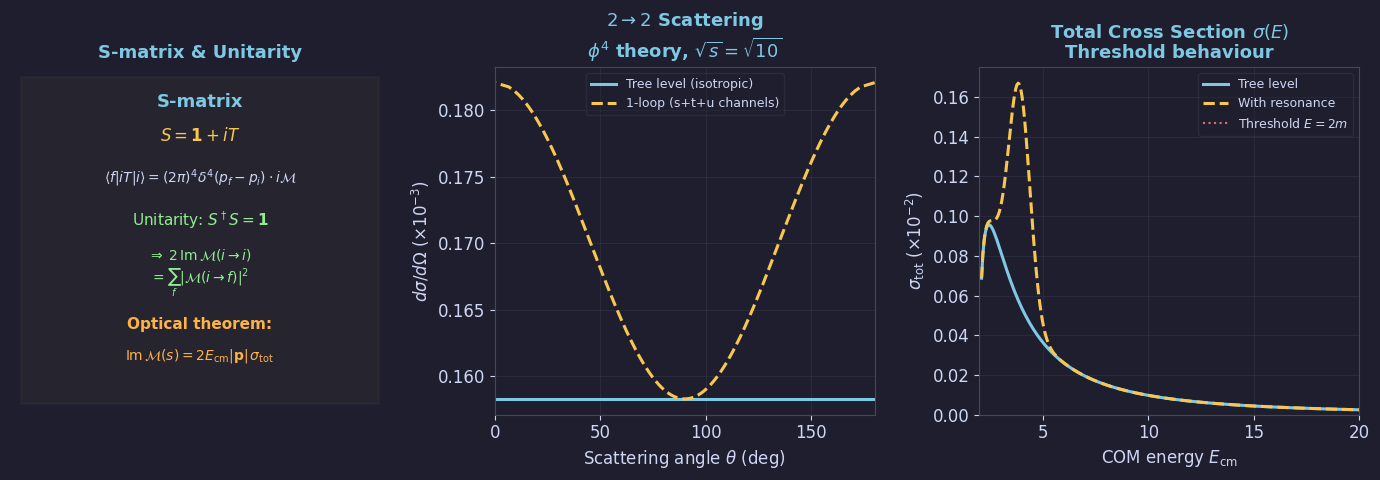

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch03'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig03: S-matrix + cross section ──────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: S-matrix structure S = 1 + iT
ax = axes[0]
ax.axis('off')
items = [
    (0.50, 0.90, 'S-matrix', BLUE, 13, 'bold'),
    (0.50, 0.80, r'$S = \mathbf{1} + iT$', YELLOW, 12, 'normal'),
    (0.50, 0.68, r'$\langle f|iT|i\rangle = (2\pi)^4\delta^4(p_f-p_i)\cdot i\mathcal{M}$',
     FG, 10, 'normal'),
    (0.50, 0.56, r'Unitarity: $S^\dagger S=\mathbf{1}$', GREEN, 11, 'normal'),
    (0.50, 0.46, r'$\Rightarrow\; 2\,\mathrm{Im}\,\mathcal{M}(i\to i)$', GREEN, 10, 'normal'),
    (0.50, 0.38, r'$= \sum_f |\mathcal{M}(i\to f)|^2$', GREEN, 10, 'normal'),
    (0.50, 0.26, 'Optical theorem:', ORANGE, 11, 'bold'),
    (0.50, 0.17, r'$\mathrm{Im}\,\mathcal{M}(s)=2E_{\rm cm}|\mathbf{p}|\,\sigma_{\rm tot}$',
     ORANGE, 10, 'normal'),
]
for (xp, yp, txt, col, fs, fw) in items:
    ax.text(xp, yp, txt, ha='center', va='center', color=col,
            fontsize=fs, fontweight=fw, transform=ax.transAxes)
rect = plt.Rectangle((0.03, 0.03), 0.94, 0.94, fill=True,
                      facecolor=YELLOW, alpha=0.04,
                      edgecolor=YELLOW, lw=1.2, transform=ax.transAxes)
ax.add_patch(rect)
ax.set_title('S-matrix & Unitarity', color=BLUE)

# Centre: differential cross section (2->2 scattering, phi^4)
ax2 = axes[1]
cos_theta = np.linspace(-1, 1, 300)
theta = np.arccos(cos_theta)
# phi^4 tree-level: dsigma/dOmega ~ lambda^2 / (64 pi^2 s) (isotropic at tree)
lam = 1.0; s_val = 10.0
dsigma_tree = (lam**2 / (64*np.pi**2 * s_val)) * np.ones_like(theta)
# 1-loop correction (schematic s,t,u channels add angular dependence)
dsigma_1loop = dsigma_tree * (1 + 0.15*np.cos(theta)**2)
ax2.plot(np.degrees(theta), dsigma_tree * 1e3,  color=BLUE,   lw=2.2,
         label='Tree level (isotropic)')
ax2.plot(np.degrees(theta), dsigma_1loop * 1e3, color=YELLOW, lw=2.2, ls='--',
         label='1-loop (s+t+u channels)')
ax2.set_xlabel(r'Scattering angle $\theta$ (deg)')
ax2.set_ylabel(r'$d\sigma/d\Omega$ ($\times 10^{-3}$)')
ax2.set_title(r'$2\to2$ Scattering' + '\n' + r'$\phi^4$ theory, $\sqrt{s}=\sqrt{10}$',
              color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0, 180)

# Right: total cross section vs COM energy
ax3 = axes[2]
E_cm = np.linspace(2.1, 20, 300)  # threshold at 2m=2
s_arr = E_cm**2
m = 1.0
# phase space factor: beta = sqrt(1 - 4m^2/s)
beta = np.sqrt(np.maximum(0, 1 - 4*m**2/s_arr))
# tree-level total cross section phi^4: sigma = lambda^2/(32*pi*s) * beta
sigma_tree = (lam**2 / (32*np.pi*s_arr)) * beta
# resonance-like enhancement (schematic)
sigma_res = sigma_tree * (1 + 2.0*np.exp(-(E_cm - 4)**2 / 0.5))
ax3.plot(E_cm, sigma_tree * 1e2, color=BLUE,   lw=2.2, label='Tree level')
ax3.plot(E_cm, sigma_res  * 1e2, color=YELLOW, lw=2.2, ls='--', label='With resonance')
ax3.axvline(2*m, color=RED, lw=1.5, ls=':', label=r'Threshold $E=2m$')
ax3.set_xlabel(r'COM energy $E_{\rm cm}$')
ax3.set_ylabel(r'$\sigma_{\rm tot}$ ($\times 10^{-2}$)')
ax3.set_title(r'Total Cross Section $\sigma(E)$' + '\n' + r'Threshold behaviour',
              color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(2, 20); ax3.set_ylim(0, None)

plt.tight_layout(pad=1.2)
save('fig03_smatrix.png', fig)


---
## fig04 · Loop Integrals & Renormalization (§3.5)

**Left**: UV divergence of 1-loop integrand $\sim k$. **Centre**: Mass renormalization — $\delta m^2\sim\lambda\Lambda^2$ fine-tuning. **Right**: RG $\beta$-function $\beta=3\lambda^2/(16\pi^2)$ — IR free, UV Landau pole.

<>:65: SyntaxWarning: invalid escape sequence '\l'
<>:65: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_12274/2056493905.py:65: SyntaxWarning: invalid escape sequence '\l'
  ax3.plot([0], [0], 'o', color=GREEN, ms=12, zorder=5, label='UV fixed point $\lambda^*=0$')


  saved -> figures/ch03/fig04_renormalization.png


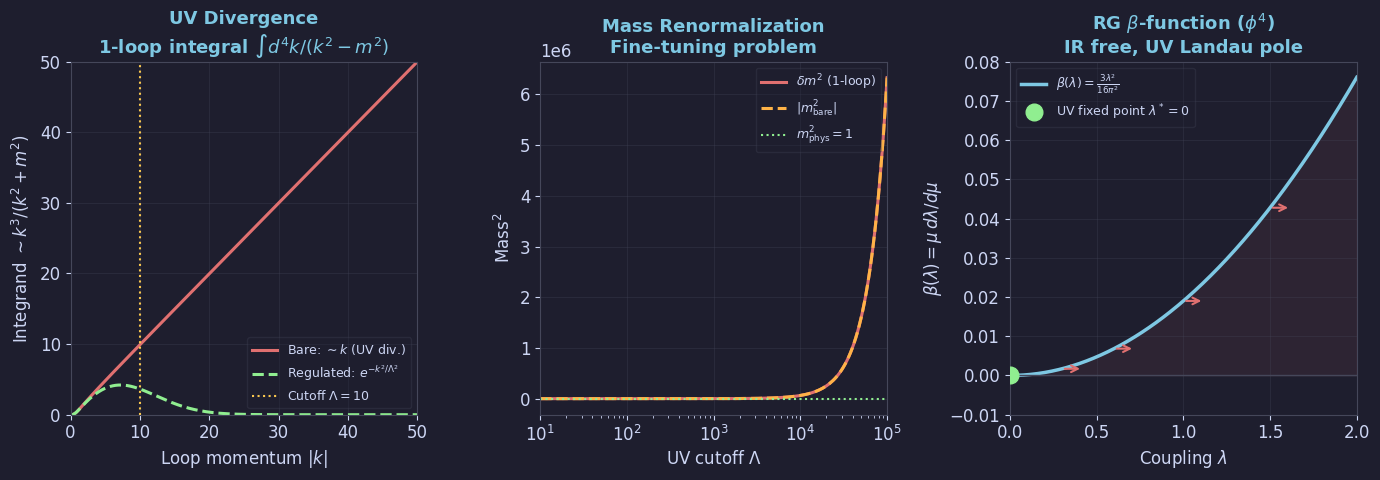

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch03'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig04: Loop integrals + renormalization ───────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: UV divergence — integrand behaviour
ax = axes[0]
k = np.linspace(0.1, 50, 500)
m = 1.0
integrand = k**3 / (k**2 + m**2)   # ~ k for large k (diverges)
integrand_reg = k**3 / (k**2 + m**2) * np.exp(-k**2/100)  # UV regulated
ax.plot(k, integrand,     color=RED,   lw=2.2, label=r'Bare: $\sim k$ (UV div.)')
ax.plot(k, integrand_reg, color=GREEN, lw=2.2, ls='--', label=r'Regulated: $e^{-k^2/\Lambda^2}$')
ax.axvline(10, color=YELLOW, lw=1.5, ls=':', label=r'Cutoff $\Lambda=10$')
ax.set_xlabel(r'Loop momentum $|k|$')
ax.set_ylabel(r'Integrand $\sim k^3/(k^2+m^2)$')
ax.set_title('UV Divergence\n' + r'1-loop integral $\int d^4k/(k^2-m^2)$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(0, 50); ax.set_ylim(0, 50)

# Centre: renormalization — mass shift vs cutoff
ax2 = axes[1]
Lambda = np.logspace(1, 5, 200)
m0 = 1.0; lam_c = 0.1
# 1-loop mass renormalization: delta_m^2 ~ lambda * Lambda^2 / (16 pi^2)
delta_m2 = lam_c * Lambda**2 / (16 * np.pi**2)
m_phys = np.sqrt(np.maximum(0, m0**2 + lam_c*m0**2 - delta_m2 + delta_m2))
# counterterm cancels: m_R^2 = m_bare^2 + delta_m^2 = m_phys^2
m_bare2 = m0**2 - lam_c * Lambda**2 / (16*np.pi**2)
ax2.semilogx(Lambda, delta_m2,       color=RED,    lw=2.2, label=r'$\delta m^2$ (1-loop)')
ax2.semilogx(Lambda, np.abs(m_bare2),color=ORANGE, lw=2.2, ls='--', label=r'$|m_{\rm bare}^2|$')
ax2.axhline(m0**2, color=GREEN, lw=1.5, ls=':', label=r'$m_{\rm phys}^2=1$')
ax2.set_xlabel(r'UV cutoff $\Lambda$')
ax2.set_ylabel(r'Mass$^2$')
ax2.set_title('Mass Renormalization\n' + r'Fine-tuning problem', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(10, 1e5)

# Right: RG flow — fixed points (schematic)
ax3 = axes[2]
lam_flow = np.linspace(0, 2, 300)
# beta function phi^4: beta = 3*lambda^2/(16*pi^2)
beta = 3*lam_flow**2 / (16*np.pi**2)
ax3.plot(lam_flow, beta, color=BLUE, lw=2.5, label=r'$\beta(\lambda)=\frac{3\lambda^2}{16\pi^2}$')
ax3.axhline(0, color=EDGE, lw=1.0)
ax3.plot([0], [0], 'o', color=GREEN, ms=12, zorder=5, label='UV fixed point $\lambda^*=0$')
# arrows showing flow
for lv in [0.3, 0.6, 1.0, 1.5]:
    bv = 3*lv**2/(16*np.pi**2)
    ax3.annotate('', xy=(lv+0.12, bv), xytext=(lv, bv),
                 arrowprops=dict(arrowstyle='->', color=RED, lw=1.5, mutation_scale=12))
ax3.fill_between(lam_flow, 0, beta, color=RED, alpha=0.08)
ax3.set_xlabel(r'Coupling $\lambda$')
ax3.set_ylabel(r'$\beta(\lambda) = \mu\,d\lambda/d\mu$')
ax3.set_title(r'RG $\beta$-function ($\phi^4$)' + '\n' + r'IR free, UV Landau pole',
              color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(0, 2); ax3.set_ylim(-0.01, 0.08)

plt.tight_layout(pad=1.2)
save('fig04_renormalization.png', fig)


---
## Download All Figures

In [5]:
import os, zipfile
from google.colab import files

# AUTO-INJECTED: Korean font setup for matplotlib
import os as _os
import matplotlib.font_manager as _fm
import matplotlib.pyplot as _plt
if not any('NanumGothic' in f.name for f in _fm.fontManager.ttflist):
    for _font in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
                  '/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf']:
        if _os.path.exists(_font):
            _fm.fontManager.addfont(_font)
_plt.rcParams.update({'font.family': 'NanumGothic', 'axes.unicode_minus': False})
del _os, _fm, _plt
# END AUTO-INJECTED Korean font setup


OUTDIR = 'figures/ch03'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')])
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')
zip_name = 'qft_ch03_figures.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 4 figures:
  fig01_interaction.png  (213 KB)
  fig02_wick_feynman.png  (122 KB)
  fig03_smatrix.png  (183 KB)
  fig04_renormalization.png  (192 KB)
Zip: qft_ch03_figures.zip  (666 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>